# English Scientific Paper Summarization with LSTM Attention

Notebook này huấn luyện mô hình **English abstractive summarization** cho paper khoa học:

\`\`\`text
English paper
→ LSTM encoder
→ additive attention
→ LSTM decoder
→ English abstract-style summary
\`\`\`


In [1]:
import importlib
import subprocess
import sys

required_distributions = []
dependency_checks = [
    ("datasets", ["datasets>=4,<5", "dill<0.4.1"]),
    ("pypdf", ["pypdf"]),
    ("bs4", ["beautifulsoup4"]),
]

for module_name, distributions in dependency_checks:
    try:
        importlib.import_module(module_name)
    except Exception:
        required_distributions.extend(distributions)

if required_distributions:
    required_distributions = list(dict.fromkeys(required_distributions))
    print("Installing:", required_distributions)
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        *required_distributions,
    ])

import json
import os
import random
import re
import time
from collections import Counter
from io import BytesIO
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import tensorflow as tf
from bs4 import BeautifulSoup
from IPython.display import Markdown, display
from pypdf import PdfReader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

QUICK_RUN = True

if QUICK_RUN:
    TRAIN_ROWS = 1_500
    VALIDATION_ROWS = 120
    TEST_ROWS = 80
    EPOCHS = 10
else:
    TRAIN_ROWS = 8_000
    VALIDATION_ROWS = 1_000
    TEST_ROWS = 500
    EPOCHS = 15

SOURCE_LENGTH = 220
TARGET_LENGTH = 56
SOURCE_VOCAB_LIMIT = 10_000
TARGET_VOCAB_LIMIT = 6_000
EMBEDDING_DIM = 64
LATENT_DIM = 96
BATCH_SIZE = 16

ROOT = Path.cwd()
DATA_DIR = ROOT / "arxiv_attention_data"
OUTPUT_DIR = ROOT / "arxiv_attention_outputs"
DATA_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Devices:", tf.config.list_physical_devices())
print({
    "quick_run": QUICK_RUN,
    "train": TRAIN_ROWS,
    "validation": VALIDATION_ROWS,
    "test": TEST_ROWS,
    "epochs": EPOCHS,
})


TensorFlow: 2.20.0
Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
{'quick_run': True, 'train': 1500, 'validation': 120, 'test': 80, 'epochs': 10}


## 1. English arXiv dataset

Notebook sử dụng [ArXiv Summarization Dataset - 20K Preprocessed](https://huggingface.co/datasets/yilmazzey/arxiv_summarization_20k_preprocessed).

Dataset có 20.000 paper tiếng Anh:

- \`article\`: full text của paper.
- \`abstract\`: abstract được dùng làm reference summary.
- Giấy phép được ghi là MIT trên trang dataset.
- Article trung bình khoảng 5.876 từ và abstract khoảng 180 từ.

Dataset chỉ có một split \`train\`. Notebook dùng \`load_dataset(..., streaming=True)\` để đọc trực tiếp file Parquet, tránh lỗi 502/429 thường gặp ở Dataset Viewer API, rồi tạo ba khoảng dữ liệu không trùng nhau:

- Train bắt đầu từ offset 0.
- Validation nằm ngay sau train.
- Test nằm sau validation.

Bản đầy đủ [ccdv/arxiv-summarization](https://huggingface.co/datasets/ccdv/arxiv-summarization) lớn hơn nhiều, phù hợp khi có GPU và dung lượng lưu trữ tốt hơn.


In [2]:
DATASET_NAME = "yilmazzey/arxiv_summarization_20k_preprocessed"


def load_raw_rows(total_rows):
    """Stream một lần từ Parquet trên Hugging Face rồi cache local."""
    combined_cache = DATA_DIR / f"streamed_0_{total_rows}.jsonl"

    if combined_cache.exists():
        print("Read cache:", combined_cache.name)
        return pd.read_json(combined_cache, lines=True)

    # Tương thích với cache do phiên bản notebook cũ đã tạo.
    legacy_train = DATA_DIR / f"train_0_{TRAIN_ROWS}.jsonl"
    legacy_holdout = DATA_DIR / (
        f"validation_{TRAIN_ROWS}_{VALIDATION_ROWS + TEST_ROWS}.jsonl"
    )

    if legacy_train.exists() and legacy_holdout.exists():
        print("Reuse legacy caches.")
        frame = pd.concat(
            [
                pd.read_json(legacy_train, lines=True),
                pd.read_json(legacy_holdout, lines=True),
            ],
            ignore_index=True,
        )[["article", "abstract"]]
        frame.to_json(
            combined_cache,
            orient="records",
            lines=True,
            force_ascii=False,
        )
        return frame

    from datasets import load_dataset
    from itertools import islice

    last_error = None

    for attempt in range(3):
        try:
            print("Streaming dataset; attempt", attempt + 1)
            stream = load_dataset(
                DATASET_NAME,
                split="train",
                streaming=True,
            )
            rows = list(islice(stream, total_rows))

            if len(rows) != total_rows:
                raise RuntimeError(
                    f"Expected {total_rows} rows, received {len(rows)}."
                )

            frame = pd.DataFrame(rows)[["article", "abstract"]]
            frame.to_json(
                combined_cache,
                orient="records",
                lines=True,
                force_ascii=False,
            )
            return frame

        except Exception as error:
            last_error = error
            wait_seconds = 10 * (attempt + 1)
            print(
                f"Streaming failed: {error}. "
                f"Retrying in {wait_seconds}s."
            )
            time.sleep(wait_seconds)

    raise RuntimeError(
        "Could not stream the arXiv dataset after 3 attempts. "
        "Restart the cell later or upload the JSONL cache."
    ) from last_error


def clean_scientific_text(text):
    text = str(text).lower()
    text = re.sub(r"@xcite", " citation ", text)
    text = re.sub(r"@xmath\d+", " formula ", text)
    text = re.sub(r"\\begin\{.*?\}|\\end\{.*?\}", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def make_encoder_excerpt(article, max_words=SOURCE_LENGTH):
    """
    Giữ khoảng 70% token đầu và 30% token cuối paper.
    Phần đầu thường chứa introduction, phần cuối thường chứa conclusion.
    """
    words = clean_scientific_text(article).split()

    if len(words) <= max_words:
        return " ".join(words)

    head_size = int(max_words * 0.70)
    tail_size = max_words - head_size

    return " ".join(
        words[:head_size]
        + ["tailsection"]
        + words[-tail_size:]
    )


def prepare_frame(frame):
    frame = frame.dropna(subset=["article", "abstract"]).copy()
    frame["full_article"] = frame["article"].map(clean_scientific_text)
    frame["article_input"] = frame["article"].map(make_encoder_excerpt)
    frame["abstract"] = frame["abstract"].map(clean_scientific_text)

    frame = frame[
        (frame["article_input"].str.split().map(len) >= 50)
        & (frame["abstract"].str.split().map(len) >= 10)
    ]

    return frame[
        ["full_article", "article_input", "abstract"]
    ].reset_index(drop=True)


total_rows = TRAIN_ROWS + VALIDATION_ROWS + TEST_ROWS
raw_df = load_raw_rows(total_rows)

train_df = prepare_frame(
    raw_df.iloc[:TRAIN_ROWS]
)
val_df = prepare_frame(
    raw_df.iloc[TRAIN_ROWS:TRAIN_ROWS + VALIDATION_ROWS]
)
test_df = prepare_frame(
    raw_df.iloc[TRAIN_ROWS + VALIDATION_ROWS:total_rows]
)

print({
    "train": len(train_df),
    "validation": len(val_df),
    "test": len(test_df),
})

display(
    train_df[["article_input", "abstract"]].head(2)
)


Streaming dataset; attempt 1


README.md:   0%|          | 0.00/2.14k [00:00<?, ?B/s]

{'train': 1500, 'validation': 120, 'test': 80}


,article_input,abstract
0,tungsten ( w ) is one of the most important co...,"calculations of energy levels , radiative rate..."
1,the understanding of the implications of non -...,we study the interplay between forgetful and m...


,article_full,article_input,abstract
count,1500.00,1500.0,1500.00
mean,5978.64,221.0,182.80
std,2917.55,0.0,81.66
min,2012.00,221.0,50.00
25%,3714.75,221.0,122.00
50%,5350.00,221.0,167.00
75%,7659.25,221.0,231.25
max,17518.00,221.0,522.00


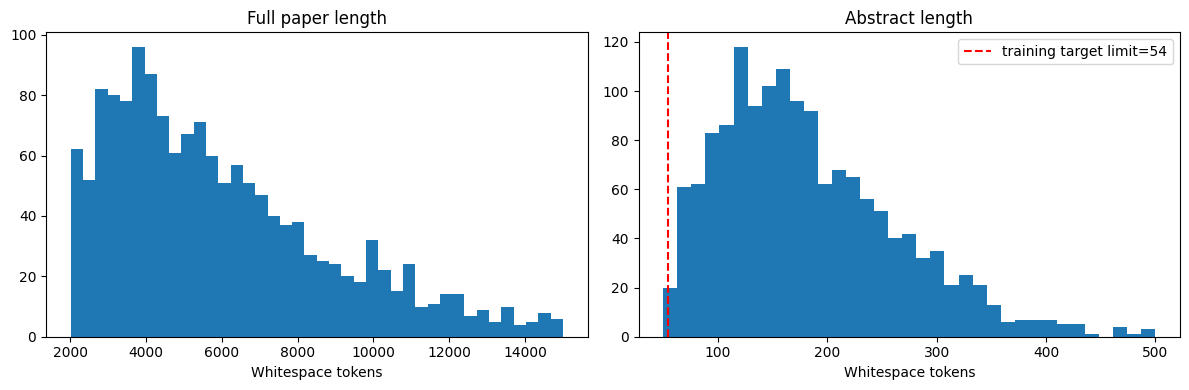

In [3]:
length_statistics = pd.DataFrame({
    "article_full": train_df["full_article"].str.split().map(len).describe(),
    "article_input": train_df["article_input"].str.split().map(len).describe(),
    "abstract": train_df["abstract"].str.split().map(len).describe(),
})
display(length_statistics.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    train_df["full_article"].str.split().map(len).clip(upper=15_000),
    bins=40,
)
axes[0].set_title("Full paper length")
axes[0].set_xlabel("Whitespace tokens")

axes[1].hist(
    train_df["abstract"].str.split().map(len).clip(upper=500),
    bins=35,
)
axes[1].axvline(
    TARGET_LENGTH - 2,
    color="red",
    linestyle="--",
    label=f"training target limit={TARGET_LENGTH - 2}",
)
axes[1].set_title("Abstract length")
axes[1].set_xlabel("Whitespace tokens")
axes[1].legend()

plt.tight_layout()
plt.show()


## 2. Vectorization and teacher forcing

Mỗi abstract được chuyển thành:

\`\`\`text
startseq abstract tokens endseq
\`\`\`

Decoder input lệch một token so với label. Padding có ID bằng 0 và không được tính vào loss/accuracy nhờ sample weight.

Vocabulary chỉ được \`adapt()\` trên train set để tránh data leakage.


In [4]:
source_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=SOURCE_VOCAB_LIMIT,
    output_mode="int",
    output_sequence_length=SOURCE_LENGTH,
    standardize=None,
    split="whitespace",
    name="source_vectorizer",
)

target_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=TARGET_VOCAB_LIMIT,
    output_mode="int",
    output_sequence_length=TARGET_LENGTH,
    standardize=None,
    split="whitespace",
    name="target_vectorizer",
)

source_vectorizer.adapt(
    train_df["article_input"].to_numpy()
)
target_vectorizer.adapt(
    np.array([
        f"startseq {abstract} endseq"
        for abstract in train_df["abstract"]
    ])
)

source_vocab = source_vectorizer.get_vocabulary()
target_vocab = target_vectorizer.get_vocabulary()

print("Source vocabulary:", len(source_vocab))
print("Target vocabulary:", len(target_vocab))


def vectorize_frame(frame):
    source_ids = source_vectorizer(
        frame["article_input"].to_numpy()
    ).numpy()

    target_text = np.array([
        f"startseq {abstract} endseq"
        for abstract in frame["abstract"]
    ])
    target_ids = target_vectorizer(target_text).numpy()

    decoder_input = target_ids[:, :-1]
    decoder_label = target_ids[:, 1:]
    sample_weight = (decoder_label != 0).astype("float32")

    return (
        source_ids,
        decoder_input,
        decoder_label,
        sample_weight,
    )


train_arrays = vectorize_frame(train_df)
val_arrays = vectorize_frame(val_df)

print("Source:", train_arrays[0].shape)
print("Decoder input:", train_arrays[1].shape)
print("Decoder label:", train_arrays[2].shape)


I0000 00:00:1791119420.324667      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791119420.328602      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Source vocabulary: 10000
Target vocabulary: 6000
Source: (1500, 220)
Decoder input: (1500, 55)
Decoder label: (1500, 55)


## 3. LSTM Encoder–Decoder with Additive Attention

Encoder trả về một representation cho mỗi source token. Decoder dùng additive attention để tính context khác nhau ở từng bước sinh abstract.

\`\`\`text
paper excerpt → Embedding → Encoder LSTM ──────┐
                                               ↓
previous summary token → Decoder LSTM → Attention
                                               ↓
                                      Dense + Softmax
                                               ↓
                                         next token
\`\`\`

Optimizer dùng gradient clipping để giảm exploding gradient.


In [5]:
def build_model():
    source_ids = tf.keras.Input(
        (SOURCE_LENGTH,),
        dtype=tf.int64,
        name="source_ids",
    )
    decoder_ids = tf.keras.Input(
        (TARGET_LENGTH - 1,),
        dtype=tf.int64,
        name="decoder_ids",
    )

    source_embedding_layer = tf.keras.layers.Embedding(
        len(source_vocab),
        EMBEDDING_DIM,
        mask_zero=True,
        name="source_embedding",
    )
    target_embedding_layer = tf.keras.layers.Embedding(
        len(target_vocab),
        EMBEDDING_DIM,
        mask_zero=True,
        name="target_embedding",
    )
    encoder_layer = tf.keras.layers.LSTM(
        LATENT_DIM,
        return_sequences=True,
        return_state=True,
        name="encoder_lstm",
    )
    decoder_layer = tf.keras.layers.LSTM(
        LATENT_DIM,
        return_sequences=True,
        return_state=True,
        name="decoder_lstm",
    )
    attention_layer = tf.keras.layers.AdditiveAttention(
        use_scale=True,
        name="additive_attention",
    )
    concatenate_layer = tf.keras.layers.Concatenate(
        name="context_and_decoder",
    )
    output_layer = tf.keras.layers.Dense(
        len(target_vocab),
        activation="softmax",
        name="token_probability",
    )

    source_embedding = source_embedding_layer(source_ids)
    encoder_outputs, encoder_h, encoder_c = encoder_layer(
        source_embedding
    )

    decoder_embedding = target_embedding_layer(decoder_ids)
    decoder_outputs, _, _ = decoder_layer(
        decoder_embedding,
        initial_state=[encoder_h, encoder_c],
    )

    context = attention_layer(
        [decoder_outputs, encoder_outputs]
    )
    combined = concatenate_layer(
        [decoder_outputs, context]
    )
    probabilities = output_layer(combined)

    model = tf.keras.Model(
        [source_ids, decoder_ids],
        probabilities,
        name="english_arxiv_lstm_attention",
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=1e-3,
            clipnorm=1.0,
        ),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(),
        weighted_metrics=[
            tf.keras.metrics.SparseCategoricalAccuracy(
                name="token_accuracy"
            )
        ],
    )

    layers = {
        "source_embedding": source_embedding_layer,
        "target_embedding": target_embedding_layer,
        "encoder": encoder_layer,
        "decoder": decoder_layer,
        "attention": attention_layer,
        "concatenate": concatenate_layer,
        "output": output_layer,
    }
    return model, layers


model, inference_layers = build_model()
model.summary()


Model: "english_arxiv_lstm_attention"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ source_ids          │ (None, 220)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_ids         │ (None, 55)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ source_embedding    │ (None, 220, 64)   │    640,000 │ source_ids[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 220)       │          0 │ source_ids[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ target_embedding    │ (None, 55, 64)    │    384,000 │ decoder_ids[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 220, 96), │     61,824 │ source_embedding… │
│                     │ (None, 96),       │            │ not_equal[0][0]   │
│                     │ (None, 96)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 55, 96),  │     61,824 │ target_embedding… │
│                     │ (None, 96),       │            │ encoder_lstm[0][… │
│                     │ (None, 96)]       │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ additive_attention  │ (None, 55, 96)    │         96 │ decoder_lstm[0][… │
│ (AdditiveAttention) │                   │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ context_and_decoder │ (None, 55, 192)   │          0 │ decoder_lstm[0][… │
│ (Concatenate)       │                   │            │ additive_attenti… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ token_probability   │ (None, 55, 6000)  │  1,158,000 │ context_and_deco… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,305,744 (8.80 MB)

 Trainable params: 2,305,744 (8.80 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
94/94 - 9s - 97ms/step - loss: 6.8182 - token_accuracy: 0.0712 - val_loss: 6.1572 - val_token_accuracy: 0.0692 - learning_rate: 0.0010
Epoch 2/10
94/94 - 3s - 35ms/step - loss: 6.1886 - token_accuracy: 0.0733 - val_loss: 6.0390 - val_token_accuracy: 0.0826 - learning_rate: 0.0010
Epoch 3/10
94/94 - 3s - 35ms/step - loss: 6.0002 - token_accuracy: 0.1143 - val_loss: 5.8588 - val_token_accuracy: 0.1418 - learning_rate: 0.0010
Epoch 4/10
94/94 - 3s - 35ms/step - loss: 5.8091 - token_accuracy: 0.1392 - val_loss: 5.7461 - val_token_accuracy: 0.1505 - learning_rate: 0.0010
Epoch 5/10
94/94 - 3s - 35ms/step - loss: 5.6773 - token_accuracy: 0.1481 - val_loss: 5.6697 - val_token_accuracy: 0.1539 - learning_rate: 0.0010
Epoch 6/10
94/94 - 3s - 35ms/step - loss: 5.5709 - token_accuracy: 0.1558 - val_loss: 5.6099 - val_token_accuracy: 0.1624 - learning_rate: 0.0010
Epoch 7/10
94/94 - 3s - 35ms/step - loss: 5.4777 - token_accuracy: 0.1670 - val_loss: 5.5650 - val_token_accuracy: 0.1685 - 

,loss,token_accuracy,val_loss,val_token_accuracy,learning_rate
0,6.8182,0.0712,6.1572,0.0692,0.001
1,6.1886,0.0733,6.0390,0.0826,0.001
2,6.0002,0.1143,5.8588,0.1418,0.001
3,5.8091,0.1392,5.7461,0.1505,0.001
4,5.6773,0.1481,5.6697,0.1539,0.001
5,5.5709,0.1558,5.6099,0.1624,0.001
6,5.4777,0.1670,5.5650,0.1685,0.001
7,5.3962,0.1759,5.5288,0.1733,0.001
8,5.3253,0.1819,5.5007,0.1774,0.001
9,5.2612,0.1879,5.4818,0.1779,0.001


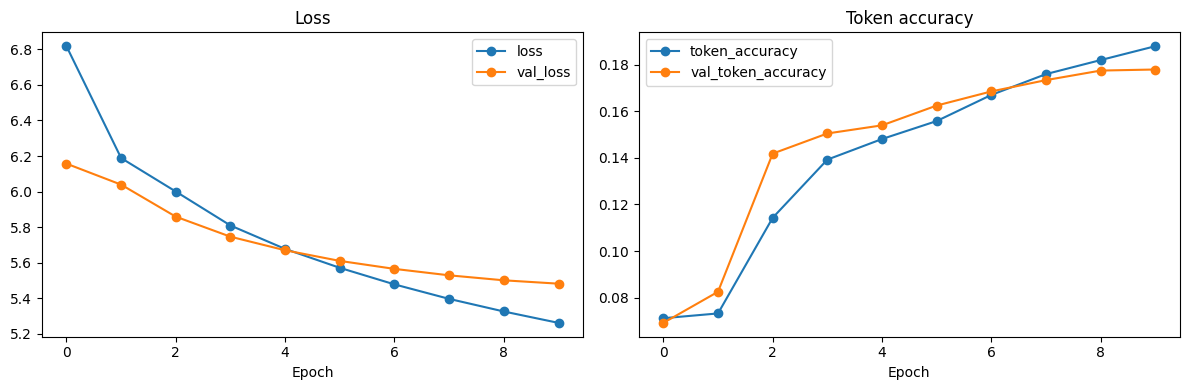

In [6]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-5,
    ),
]

started_at = time.perf_counter()

history = model.fit(
    [train_arrays[0], train_arrays[1]],
    train_arrays[2],
    sample_weight=train_arrays[3],
    validation_data=(
        [val_arrays[0], val_arrays[1]],
        val_arrays[2],
        val_arrays[3],
    ),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=2,
)

training_seconds = time.perf_counter() - started_at
history_df = pd.DataFrame(history.history)

print(f"Training time: {training_seconds:.1f} seconds")
display(history_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
history_df[["loss", "val_loss"]].plot(
    ax=axes[0],
    marker="o",
)
history_df[
    ["token_accuracy", "val_token_accuracy"]
].plot(
    ax=axes[1],
    marker="o",
)
axes[0].set_title("Loss")
axes[1].set_title("Token accuracy")
for axis in axes:
    axis.set_xlabel("Epoch")

plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "training_history.png",
    dpi=140,
    bbox_inches="tight",
)
plt.show()


In [7]:
target_to_id = {
    token: index
    for index, token in enumerate(target_vocab)
}
START_ID = target_to_id["startseq"]
END_ID = target_to_id["endseq"]


def decode_summary(text, return_attention=False):
    source_np = source_vectorizer(
        np.array([clean_scientific_text(text)])
    ).numpy()
    source_ids = tf.constant(source_np)
    source_mask = tf.not_equal(source_ids, 0)

    source_embedding = inference_layers[
        "source_embedding"
    ](source_ids)
    encoder_outputs, state_h, state_c = inference_layers[
        "encoder"
    ](
        source_embedding,
        training=False,
    )

    current_token = tf.constant(
        [[START_ID]],
        dtype=tf.int64,
    )
    generated = []
    attention_rows = []

    for _ in range(TARGET_LENGTH - 1):
        decoder_embedding = inference_layers[
            "target_embedding"
        ](current_token)

        decoder_output, state_h, state_c = inference_layers[
            "decoder"
        ](
            decoder_embedding,
            initial_state=[state_h, state_c],
            training=False,
        )

        context, scores = inference_layers["attention"](
            [decoder_output, encoder_outputs],
            mask=[
                tf.ones((1, 1), dtype=tf.bool),
                source_mask,
            ],
            return_attention_scores=True,
            training=False,
        )

        combined = inference_layers["concatenate"](
            [decoder_output, context]
        )
        probabilities = inference_layers["output"](
            combined,
            training=False,
        )

        predicted_id = int(
            tf.argmax(probabilities[0, 0]).numpy()
        )

        if predicted_id in (0, END_ID):
            break

        token = target_vocab[predicted_id]
        if token not in {"[UNK]", "startseq"}:
            generated.append(token)
            attention_rows.append(scores[0, 0].numpy())

        current_token = tf.constant(
            [[predicted_id]],
            dtype=tf.int64,
        )

    summary = " ".join(generated)

    if return_attention:
        return summary, np.array(attention_rows), source_np[0]
    return summary


In [8]:
def ngram_counts(tokens, n):
    return Counter(
        tuple(tokens[index:index + n])
        for index in range(len(tokens) - n + 1)
    )


def rouge_n_f1(reference, prediction, n):
    reference_tokens = reference.split()
    prediction_tokens = prediction.split()
    reference_counts = ngram_counts(reference_tokens, n)
    prediction_counts = ngram_counts(prediction_tokens, n)
    overlap = sum(
        (reference_counts & prediction_counts).values()
    )

    precision = overlap / max(
        1,
        sum(prediction_counts.values()),
    )
    recall = overlap / max(
        1,
        sum(reference_counts.values()),
    )

    return 2 * precision * recall / max(
        1e-12,
        precision + recall,
    )


def rouge_l_f1(reference, prediction):
    reference_tokens = reference.split()
    prediction_tokens = prediction.split()
    previous = [0] * (len(prediction_tokens) + 1)

    for reference_token in reference_tokens:
        current = [0]
        for index, prediction_token in enumerate(
            prediction_tokens,
            start=1,
        ):
            if reference_token == prediction_token:
                current.append(previous[index - 1] + 1)
            else:
                current.append(
                    max(current[-1], previous[index])
                )
        previous = current

    lcs = previous[-1]
    precision = lcs / max(1, len(prediction_tokens))
    recall = lcs / max(1, len(reference_tokens))

    return 2 * precision * recall / max(
        1e-12,
        precision + recall,
    )


def evaluate(frame, predict_fn, model_name):
    records = []

    for position, row in frame.reset_index(drop=True).iterrows():
        prediction = predict_fn(row["article_input"])
        reference = row["abstract"]

        records.append({
            "model": model_name,
            "reference": reference,
            "prediction": prediction,
            "rouge1": rouge_n_f1(reference, prediction, 1),
            "rouge2": rouge_n_f1(reference, prediction, 2),
            "rougeL": rouge_l_f1(reference, prediction),
        })

        if (position + 1) % 20 == 0:
            print(f"{model_name}: {position + 1}/{len(frame)}")

    predictions = pd.DataFrame(records)
    scores = predictions[
        ["rouge1", "rouge2", "rougeL"]
    ].mean()
    scores.name = model_name

    return predictions, scores


def lead_54_tokens(text):
    return " ".join(text.split()[:TARGET_LENGTH - 2])


model_predictions, model_scores = evaluate(
    test_df,
    decode_summary,
    "LSTM + Attention",
)
lead_predictions, lead_scores = evaluate(
    test_df,
    lead_54_tokens,
    "Lead-54 baseline",
)

score_table = pd.concat(
    [model_scores, lead_scores],
    axis=1,
).T
display(score_table.style.format("{:.4f}"))


LSTM + Attention: 20/80
LSTM + Attention: 40/80
LSTM + Attention: 60/80
LSTM + Attention: 80/80
Lead-54 baseline: 20/80
Lead-54 baseline: 40/80
Lead-54 baseline: 60/80
Lead-54 baseline: 80/80


,rouge1,rouge2,rougeL
LSTM + Attention,0.2523,0.0444,0.1975
Lead-54 baseline,0.2398,0.0580,0.1522


In [9]:
comparison = model_predictions.copy()
comparison = comparison.rename(
    columns={"prediction": "attention_prediction"}
)
comparison["lead_prediction"] = lead_predictions["prediction"]
comparison["paper_excerpt"] = test_df["article_input"]

display(
    comparison[
        [
            "reference",
            "attention_prediction",
            "lead_prediction",
            "rouge1",
            "rouge2",
            "rougeL",
        ]
    ].head(5)
)

results = {
    "dataset": DATASET_NAME,
    "mode": "quick" if QUICK_RUN else "long",
    "seed": SEED,
    "train_examples": len(train_df),
    "validation_examples": len(val_df),
    "test_examples": len(test_df),
    "epochs_completed": len(history.history["loss"]),
    "training_seconds": float(training_seconds),
    "source_length": SOURCE_LENGTH,
    "target_length": TARGET_LENGTH,
    "source_vocabulary": len(source_vocab),
    "target_vocabulary": len(target_vocab),
    "lstm_attention": {
        key: float(value)
        for key, value in model_scores.items()
    },
    "lead_54_baseline": {
        key: float(value)
        for key, value in lead_scores.items()
    },
    "history": {
        key: [float(value) for value in values]
        for key, values in history.history.items()
    },
}

(OUTPUT_DIR / "results.json").write_text(
    json.dumps(results, indent=2),
    encoding="utf-8",
)
comparison.to_csv(
    OUTPUT_DIR / "test_predictions.csv",
    index=False,
    encoding="utf-8",
)
(OUTPUT_DIR / "source_vocabulary.txt").write_text(
    "\n".join(source_vocab),
    encoding="utf-8",
)
(OUTPUT_DIR / "target_vocabulary.txt").write_text(
    "\n".join(target_vocab),
    encoding="utf-8",
)
model.save(
    OUTPUT_DIR / "english_arxiv_attention.keras"
)

display(Markdown(f"""
## 4. Training report

- Train: **{len(train_df):,} papers**
- Validation: **{len(val_df):,} papers**
- Test: **{len(test_df):,} papers**
- Epochs: **{len(history.history["loss"])}**
- Training time: **{training_seconds:.1f} seconds**

| Model | ROUGE-1 F1 | ROUGE-2 F1 | ROUGE-L F1 |
|---|---:|---:|---:|
| LSTM + Attention | {model_scores["rouge1"]:.4f} | {model_scores["rouge2"]:.4f} | {model_scores["rougeL"]:.4f} |
| Lead-54 baseline | {lead_scores["rouge1"]:.4f} | {lead_scores["rouge2"]:.4f} | {lead_scores["rougeL"]:.4f} |

ROUGE ở đây là implementation whitespace-tokenized để notebook tự chạy. Không so trực tiếp với paper sử dụng tokenizer hoặc package ROUGE khác.
"""))


,reference,attention_prediction,lead_prediction,rouge1,rouge2,rougeL
0,we report on imaging and spectroscopic observa...,we present the of the of the - ( ) ) in the - ...,"in the late eighties , optical imaging surveys...",0.278027,0.063348,0.197309
1,using the mathisson - papapetrou - dixon ( mpd...,we present the of the of the - ( ) ) in the - ...,the geodesics in a kerr metric are considered ...,0.366667,0.044944,0.244444
2,the long - distance structure of the interacti...,we present the of the of the - ( ) ) in the - ...,as much as a desire to understand bound state ...,0.297619,0.048193,0.250000
3,recently several studies have jointly analysed...,we present the of the of the of the - ( ) ) in...,several groups ( e.g. eisenstein et al . 1999 ...,0.291457,0.030457,0.211055
4,there is a large body of evidence for the pote...,we present the of the of the - ( ) ) in the - ...,there is a growing sense of excitement that in...,0.207171,0.048193,0.175299



## 4. Training report

- Train: **1,500 papers**
- Validation: **120 papers**
- Test: **80 papers**
- Epochs: **10**
- Training time: **38.8 seconds**

| Model | ROUGE-1 F1 | ROUGE-2 F1 | ROUGE-L F1 |
|---|---:|---:|---:|
| LSTM + Attention | 0.2523 | 0.0444 | 0.1975 |
| Lead-54 baseline | 0.2398 | 0.0580 | 0.1522 |

ROUGE ở đây là implementation whitespace-tokenized để notebook tự chạy. Không so trực tiếp với paper sử dụng tokenizer hoặc package ROUGE khác.


Reference: we report on imaging and spectroscopic observations of the radio - loud , highly polarized quasar pks 1610771 ( formula = 1.71 ) . our long - slit spectroscopy of the companion 4.55 nw of the quasar confirms the stellar nature of this object , so ruling out the previously suspected gravitationally lensed nature of this system . pks 1610771 looks fuzzy on our sub - arcsecond formula and formula images and appears located in a rich environment of faint galaxies . possible magnification , without image splitting of the quasar itself , by some of these maybe foreground galaxies can not be excluded . the continuum fuzz ( made of the closest two objects , viz . a and d ) is elongated in a direction orthogonal to the formula vector of the optical polarization , as in high - redshift radio - galaxies . the spectrum of pks 1610771 appears strongly curved , in a convex way , with a maximum of intensity at formula 7,600 formula ( 2,800 formula rest frame ) , possibly indicating a stron

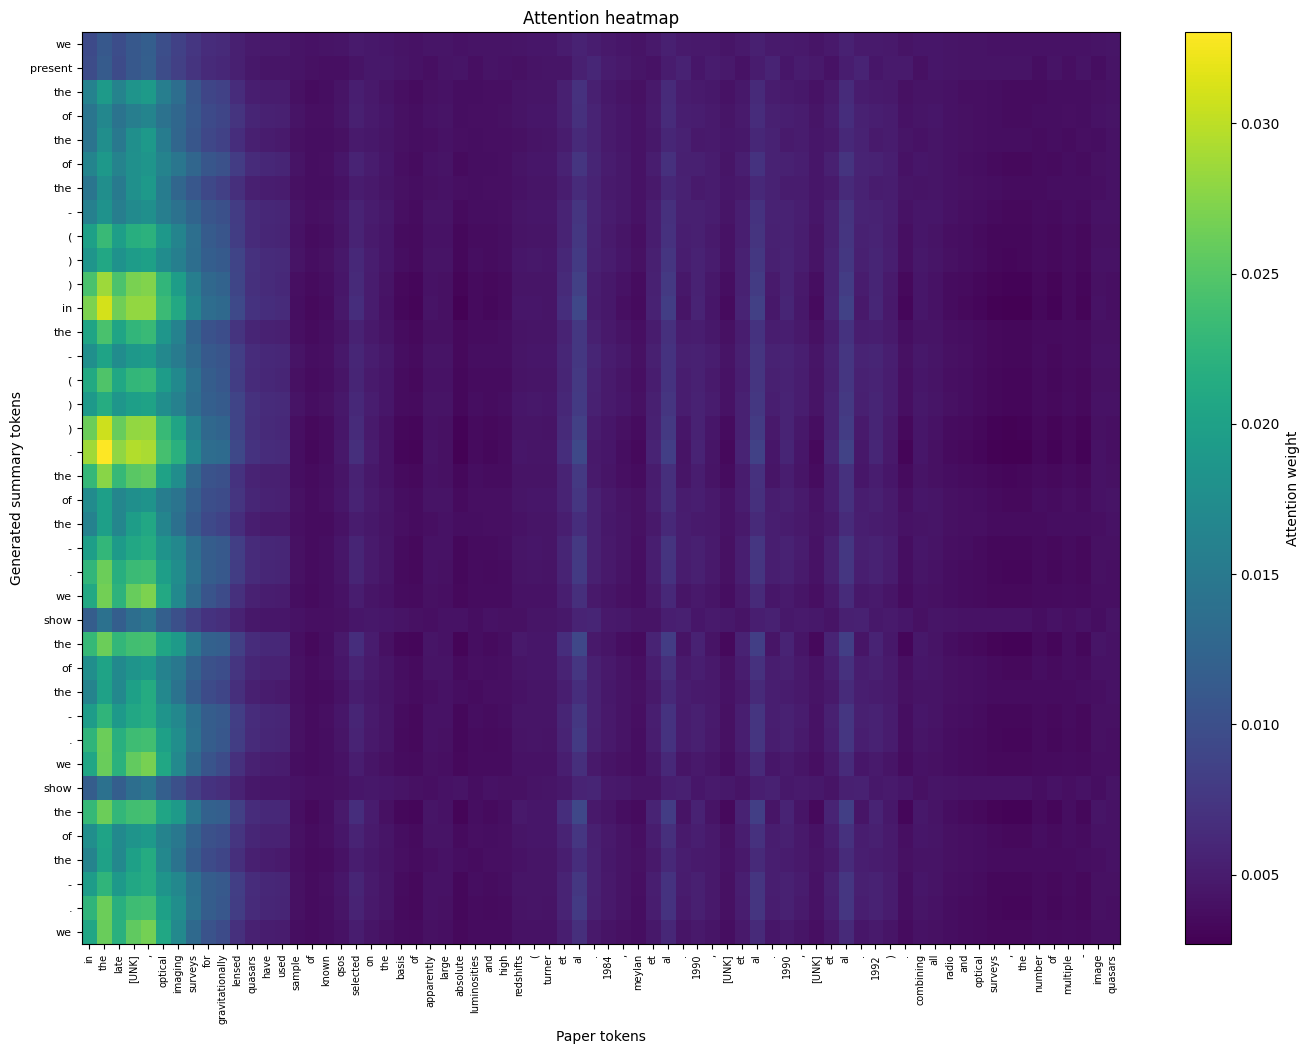

In [10]:
example = test_df.iloc[0]
generated, attention_matrix, source_id_row = decode_summary(
    example["article_input"],
    return_attention=True,
)

source_tokens = [
    source_vocab[int(token_id)]
    for token_id in source_id_row
    if token_id != 0
]
generated_tokens = generated.split()

print("Reference:", example["abstract"])
print("Prediction:", generated)

if generated_tokens and attention_matrix.size:
    visible_source = source_tokens[:70]
    visible_attention = attention_matrix[
        :len(generated_tokens),
        :len(visible_source),
    ]

    plt.figure(
        figsize=(
            max(14, len(visible_source) * 0.20),
            max(4, len(generated_tokens) * 0.28),
        )
    )
    plt.imshow(
        visible_attention,
        aspect="auto",
        cmap="viridis",
    )
    plt.colorbar(label="Attention weight")
    plt.xticks(
        range(len(visible_source)),
        visible_source,
        rotation=90,
        fontsize=7,
    )
    plt.yticks(
        range(len(generated_tokens)),
        generated_tokens,
        fontsize=8,
    )
    plt.xlabel("Paper tokens")
    plt.ylabel("Generated summary tokens")
    plt.title("Attention heatmap")
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / "attention_heatmap.png",
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
else:
    print("No valid generated tokens for the heatmap.")


## 5. URL → English paper summary

Pipeline nhận URL PDF/HTML hoặc arXiv abstract URL:

\`\`\`text
paper URL
→ extract English text
→ split into representative chunks
→ summarize each chunk
→ summarize intermediate summaries
→ final English summary
\`\`\`

Cài dependency nếu cần:

\`\`\`python
%pip install pypdf beautifulsoup4
\`\`\`

Pipeline giới hạn 50 MB, tối đa 40 trang và chặn localhost/mạng nội bộ. PDF scan không có text cần OCR riêng.


In [11]:
import ipaddress
import socket
from urllib.parse import urlparse

MAX_DOWNLOAD_BYTES = 50 * 1024 * 1024


def normalize_paper_url(url):
    url = str(url).strip()
    parsed = urlparse(url)

    if parsed.scheme not in {"http", "https"} or not parsed.hostname:
        raise ValueError("URL must start with http:// or https://")

    if (
        parsed.hostname.lower() in {"arxiv.org", "www.arxiv.org"}
        and parsed.path.startswith("/abs/")
    ):
        arxiv_id = parsed.path.removeprefix("/abs/").strip("/")
        return f"https://arxiv.org/pdf/{arxiv_id}"

    return url


def ensure_public_url(url):
    parsed = urlparse(url)
    hostname = parsed.hostname

    if not hostname:
        raise ValueError("Invalid hostname.")

    addresses = {
        item[4][0]
        for item in socket.getaddrinfo(
            hostname,
            parsed.port or 443,
        )
    }

    for address in addresses:
        ip = ipaddress.ip_address(address)
        if (
            ip.is_private
            or ip.is_loopback
            or ip.is_link_local
            or ip.is_multicast
            or ip.is_reserved
            or ip.is_unspecified
        ):
            raise ValueError(
                "Local and private network URLs are not allowed."
            )


def download_paper(url, max_bytes=MAX_DOWNLOAD_BYTES):
    normalized_url = normalize_paper_url(url)
    ensure_public_url(normalized_url)

    with requests.get(
        normalized_url,
        headers={
            "User-Agent": (
                "Mozilla/5.0 "
                "(compatible; English-Paper-Summarizer/1.0)"
            )
        },
        timeout=(10, 90),
        stream=True,
        allow_redirects=True,
    ) as response:
        response.raise_for_status()
        ensure_public_url(response.url)

        parts = []
        downloaded = 0

        for part in response.iter_content(64 * 1024):
            if not part:
                continue

            downloaded += len(part)
            if downloaded > max_bytes:
                raise ValueError("Paper exceeds the 50 MB limit.")
            parts.append(part)

        content_type = (
            response.headers
            .get("Content-Type", "")
            .split(";")[0]
            .lower()
        )

        return {
            "content": b"".join(parts),
            "content_type": content_type,
            "final_url": response.url,
            "downloaded_bytes": downloaded,
        }


def extract_paper_text(url, max_pages=40):
    downloaded = download_paper(url)
    content = downloaded["content"]
    final_url = downloaded["final_url"]

    is_pdf = (
        content.startswith(b"%PDF")
        or downloaded["content_type"] == "application/pdf"
        or urlparse(final_url).path.lower().endswith(".pdf")
    )

    if is_pdf:
        reader = PdfReader(BytesIO(content))
        page_limit = min(len(reader.pages), max_pages)
        pages = [
            reader.pages[index].extract_text() or ""
            for index in range(page_limit)
        ]
        text = " ".join(pages)
        metadata = {
            "format": "pdf",
            "page_count": len(reader.pages),
            "pages_read": page_limit,
            "title": "",
        }
    else:
        soup = BeautifulSoup(content, "html.parser")

        for tag in soup([
            "script", "style", "noscript", "nav",
            "header", "footer", "form", "aside",
        ]):
            tag.decompose()

        main = (
            soup.find("article")
            or soup.find("main")
            or soup.body
            or soup
        )
        text = main.get_text(" ", strip=True)
        metadata = {
            "format": "html",
            "page_count": None,
            "pages_read": None,
            "title": (
                soup.title.string.strip()
                if soup.title and soup.title.string
                else ""
            ),
        }

    text = clean_scientific_text(text)

    if len(text.split()) < 50:
        raise ValueError(
            "Too little text was extracted. "
            "The page may require login, JavaScript, or OCR."
        )

    return {
        **downloaded,
        **metadata,
        "text": text,
    }


In [12]:
def create_chunks(
    text,
    chunk_words=200,
    overlap_words=30,
    max_chunks=8,
):
    words = clean_scientific_text(text).split()
    step = max(1, chunk_words - overlap_words)

    chunks = [
        " ".join(words[start:start + chunk_words])
        for start in range(0, len(words), step)
        if words[start:start + chunk_words]
    ]

    if len(chunks) <= max_chunks:
        return chunks

    indices = np.linspace(
        0,
        len(chunks) - 1,
        num=max_chunks,
        dtype=int,
    )
    return [chunks[index] for index in indices]


def summarize_paper_url(
    url,
    max_pages=40,
    max_chunks=8,
):
    extracted = extract_paper_text(
        url,
        max_pages=max_pages,
    )
    chunks = create_chunks(
        extracted["text"],
        chunk_words=SOURCE_LENGTH - 20,
        overlap_words=30,
        max_chunks=max_chunks,
    )

    chunk_summaries = []

    for index, chunk in enumerate(chunks, start=1):
        summary = decode_summary(chunk).strip()
        if summary:
            chunk_summaries.append(summary)
        print(f"Summarized chunk {index}/{len(chunks)}")

    if not chunk_summaries:
        final_summary = ""
    elif len(chunk_summaries) == 1:
        final_summary = chunk_summaries[0]
    else:
        combined = " ".join(chunk_summaries)
        final_summary = decode_summary(combined).strip()
        if not final_summary:
            final_summary = combined

    return {
        "url": url,
        "final_url": extracted["final_url"],
        "title": extracted["title"],
        "format": extracted["format"],
        "page_count": extracted["page_count"],
        "pages_read": extracted["pages_read"],
        "paper_word_count": len(extracted["text"].split()),
        "chunks_used": len(chunks),
        "chunk_summaries": chunk_summaries,
        "summary": final_summary,
    }


# Dán URL paper tiếng Anh vào đây rồi chạy lại cell.
PAPER_URL = "https://arxiv.org/abs/1706.03762"

if PAPER_URL.strip():
    paper_result = summarize_paper_url(PAPER_URL)

    display(Markdown(f"""
### Paper summary

- **Final URL:** {paper_result["final_url"]}
- **Format:** {paper_result["format"]}
- **Extracted words:** {paper_result["paper_word_count"]:,}
- **Chunks:** {paper_result["chunks_used"]}
- **Pages:** {paper_result["page_count"] or "Unknown"}

**English summary**

{paper_result["summary"] or "The model produced no summary."}
"""))

    display(pd.DataFrame({
        "chunk": range(
            1,
            len(paper_result["chunk_summaries"]) + 1,
        ),
        "summary": paper_result["chunk_summaries"],
    }))
else:
    print(
        "Set PAPER_URL and run this cell. "
        "Example: PAPER_URL = 'https://arxiv.org/abs/1409.0473'"
    )


Summarized chunk 1/8
Summarized chunk 2/8
Summarized chunk 3/8
Summarized chunk 4/8
Summarized chunk 5/8
Summarized chunk 6/8
Summarized chunk 7/8
Summarized chunk 8/8



### Paper summary

- **Final URL:** https://arxiv.org/pdf/1706.03762
- **Format:** pdf
- **Extracted words:** 6,022
- **Chunks:** 8
- **Pages:** 15

**English summary**

we present the of the - ( ) in the - ( ) ) in the - . the - . the - . the - . the - . the


,chunk,summary
0,1,we present the of the - ( ) in the - ( ) ) in ...
1,2,we present the of the of the - ( ) ) in the - ...
2,3,"we present the of the - , in the . the , the ...."
3,4,we present the of the of the of the - ( ) ) in...
4,5,we present the of the - ( ) ) in the - ( ) ) i...
5,6,"we present the of the - . the , the . the , th..."
6,7,we present the of the - ( ) ) in the - ( ) ) i...
7,8,we present the of the of the of the of the of ...
